# Training Flow Matching Models

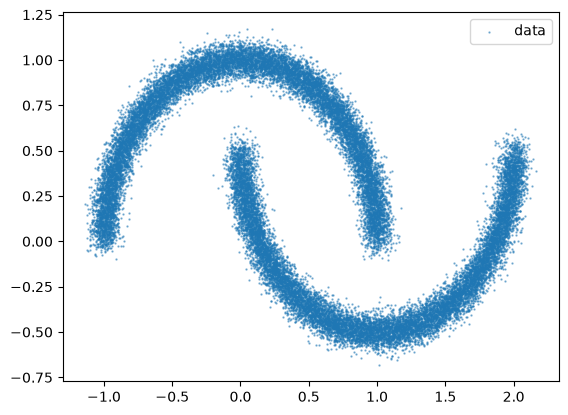

In [1]:
import jax
import jax.numpy as jnp
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt
from flowMC.resource.model.common import MLP
from flowMC.resource.model.flowmatching.base import (
    Solver,
    Path,
    CondOTScheduler,
    FlowMatchingModel,
)

# Optimization parameters
num_epochs = 5000
batch_size = 30000
learning_rate = 1e-3
momentum = 0.9
n_samples = 30000
seed = 0

solver = Solver(
    MLP([3, 128, 128, 128, 2], jax.random.PRNGKey(0), activation=jax.nn.swish)
)
path = Path(CondOTScheduler())
model = FlowMatchingModel(solver, path)

data = jnp.array(make_moons(n_samples, noise=0.05)[0])

plt.scatter(data[:, 0], data[:, 1], s=0.5, alpha=0.5, label="data")
plt.legend()
plt.show()

In [2]:
import optax  # Optimizers
import equinox as eqx  # Equinox

key = jax.random.PRNGKey(seed)

key, subkey = jax.random.split(key)
x0 = jax.random.normal(subkey, (data.shape[0], 2))  # Initial points
key, subkey = jax.random.split(key)
t = jax.random.uniform(
    subkey, (data.shape[0], 1), minval=0.0, maxval=1.0
)  # Random time points

optim = optax.adam(learning_rate)
state = optim.init(eqx.filter(model, eqx.is_inexact_array))
key, subkey = jax.random.split(key)
key, trained_model, state, loss = model.train(
    key, (x0, data, t), optim, state, num_epochs, batch_size, verbose=True
)

Training NF, current loss: 1.369: 100%|██████████| 5000/5000 [00:34<00:00, 146.56it/s]


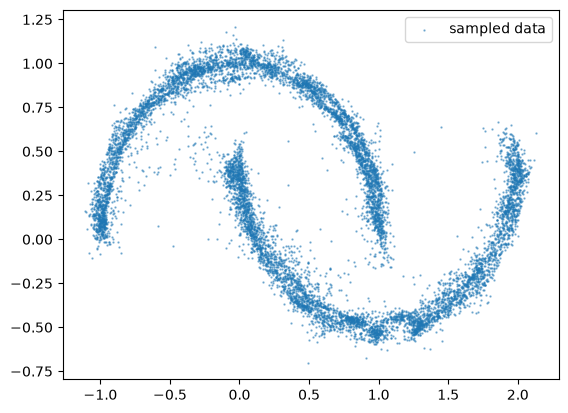

In [3]:
sampled_data = trained_model.sample(key, 10000, dt=0.1)
plt.scatter(
    sampled_data[:, 0], sampled_data[:, 1], s=0.5, alpha=0.5, label="sampled data"
)
plt.legend()
plt.show()

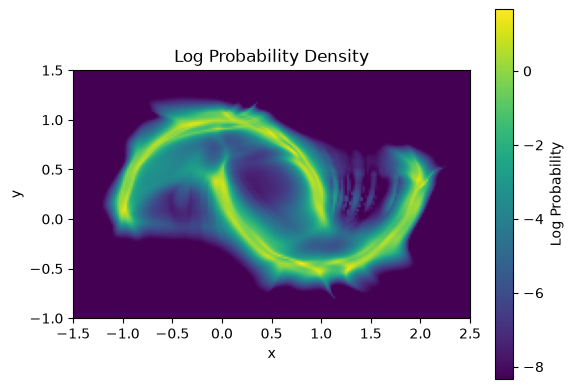

In [4]:
x, y = jnp.mgrid[-1.5:2.5:200j, -1.0:1.5:125j]
grid = jnp.stack([x.ravel(), y.ravel()], axis=1)
log_prob = eqx.filter_vmap(trained_model.log_prob)(grid).reshape(x.shape)
plt.imshow(
    log_prob.T,
    extent=(-1.5, 2.5, -1.0, 1.5),
    origin="lower",
    cmap="viridis",
    vmin=log_prob.max() - 10,
)
plt.colorbar(label="Log Probability")
plt.title("Log Probability Density")
plt.xlabel("x")
plt.ylabel("y")
plt.show()